# Chapter4 : 신경망 학습

# 4.1 데이터에서 학습한다!
## 4.1.1 데이터 주도 학습
### 머신러닝
- 머신러닝에서는 데이터가 생명
- 데이터로 답을 찾고, 데이터에서 패턴을 발견, 이야기를 만듦
### 머신러닝 VS 딥러닝
> 머신러닝 : 데이터 -> 사람이 생각한 특징 (SIFT,HOG) -> 머신러닝 (SVM, KNN) -> 결과
>
> 딥러닝 : 데이터 -> 신경망(딥러닝) -> 결과

## 4.1.2 훈련 데이터와 시험 데이터
### 훈련 데이터 (Training data)
- 훈련 데이터로 학습시키며, 최적의 매개변수를 찾음

### 시험 데이터 (Test data)
- 시험 데이터를 이용하여 앞서 훈련한 모델의 실력을 평가

> 범용능력(새로운 데이터를 봤을때도 모델의 성능이 떨어지면 안 됌)을 평가하기 위함

과대적합(overfiting) - 한 데이터셋에만 지나치게 최적화된 상태

## 4.2 손실 함수 (Loss Function)
- 손실 함수를 기준으로 최적의 매개변수 값을 탐색

### 4.2.1 오차제곱합 (SSE : Sum of Squares for Error)
$$ E = \frac{1}{2} \sum_k (y_k-t_k)^2 $$
- $y_k$는 신경망의 출력
- $t_k$는 정답 레이블
- $k$는 데이터의 차원 수

예) 손글씨 숫자 인식
```
y = [0.1, 0.05, 0.6, 0.0, 0.05, 0.1, 0.0, 0.1, 0.0, 0.0]
t = [0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
```
- y가 출력, t가 원핫 인코딩인 정답 레이블

In [108]:
import numpy as np
def sum_squares_error(y,t):
  return 0.5 * np.sum((y-t)**2)

# 정답은 '2'
t = [0, 0, 1, 0, 0, 0, 0, 0, 0, 0]

# 예1 : '2'일 확률이 가장 높다고 추정함 (0.6)
y = [0.1, 0.05, 0.6, 0.0, 0.05, 0.1, 0.0, 0.1, 0.0, 0.0]
print(sum_squares_error(np.array(y), np.array(t)))
# 0.09750000000000003

# 예2 : '7'일 확률이 가장 높다고 추정함 (0.6)
y = [0.1, 0.05, 0.1, 0.0, 0.05, 0.1, 0.0, 0.6, 0.0, 0.0]
print(sum_squares_error(np.array(y), np.array(t)))
# 0.5975

0.09750000000000003
0.5975


## 4.2.2 교차 엔트로피 오차 (CEE : Cross Entropy Error)
$$ E = -\sum_k t_k\ln y_k$$

- $y_k$는 신경망의 출력
- $t_k$는 정답 레이블
- $k$는 데이터의 차원 수

손글씨 정답 라벨은 오답이 0이기 때문에, 정답일때늬 출력이 전체 값 결정

In [109]:
def cross_entropy_error(y,t):
  delta = 1e-7
  return -np.sum(t * np.log(y + delta)) # delta를 더하는 이유 log0을 방지

t = [0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
# 2일 확률이 가장 높다고 추정
y = [0.1, 0.05, 0.6, 0.0, 0.05, 0.1, 0.0, 0.1, 0.0, 0.0]
print(cross_entropy_error(np.array(y), np.array(t)))
# 0.510825457099338

# 7일 확률이 가장 높다고 추정
y =[0.1, 0.05, 0.1,0.0, 0.05, 0.1,0.0, 0.6, 0.0, 0.0]
print(cross_entropy_error(np.array(y), np.array(t)))
# 2.302584092994546

0.510825457099338
2.302584092994546


## 4.2.3 미니배치 학습
- 모든 훈련 데이터를 대상으로 손실함수 값을 구해야함

$$ E = -\frac{1}{N}\sum_n\sum_k t_{nk}\log y_{nk} $$
- 데이터 N개
- t_nk : n번째 데이터의 k번째 값
(y_nk는 신경망의 출력, t_nk는 정답 라벨)

### 미니배치 학습 : 훈련 데이터로부터 일부만 뽑아서 학습을 수행
- 많은 데이터를 전부다 손실함수를 계산하기에는 어렵기 때문


In [110]:
!git clone https://github.com/WegraLee/deep-learning-from-scratch.git
%cd deep-learning-from-scratch

Cloning into 'deep-learning-from-scratch'...
remote: Enumerating objects: 1118, done.
remote: Counting objects: 100% (175/175), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 1118 (delta 141), reused 130 (delta 130), pack-reused 943 (from 2)
Receiving objects: 100% (1118/1118), 52.68 MiB | 39.04 MiB/s, done.
Resolving deltas: 100% (644/644), done.
/content/deep-learning-from-scratch/deep-learning-from-scratch/deep-learning-from-scratch/deep-learning-from-scratch/deep-learning-from-scratch/deep-learning-from-scratch


In [111]:
from dataset.mnist import load_mnist

(x_train, t_train), (x_test, t_test) = \
  load_mnist(normalize=True, one_hot_label=True)

print(x_train.shape) # (60000, 784)
print(t_train.shape) # (60000, 10)

(60000, 784)
(60000, 10)


- x : 훈련 데이터는 60000개, 입력 데이터는 784 (28*28)개
- t : 정답 레이블 10줄 짜리 데이터

np.random.choice() 함수를 이용하면 훈련 데이터에서 무작위로 10장 빼기 가능

```
train_size = x_train.shape[0]
batch_size = 10
batch_mask = np.random.choice(train_size, batch_size)
x_batch = x_train[batch_mask]
t_bacth = y_train[bacth_mask]
```

In [112]:
print(np.random.choice(60000,10))

[34251 57918 24258 10893 15091 15405 57146 38216 54793 37034]


## 4.2.4 (배치용) 교차 엔트로피 오차 구하기
- 데이터가 하나인 경우와 배치로 묶여 입력이 되는 경우 모두 처리가능하게 구현

In [113]:
def cross_entropy_error(y, t):
  if y.ndim == 1:
    t = t.reshape(1, t.size)
    y = y.reshape(1, y.size)

  batch_size = y. shape[0]
  return -np.sum(t * np.log(y + 1e-7)) / batch_size

- y가 1차원인 경우, 즉 데이터 하나당 교차 엔트로피 오차를 구하는 경우 reshape함수로 데이터의 형상을 바꿔줌
- 배치의 크기로 나눠서 정규화 하고, 이미지 1장당 평균 엔트로피 오차를 계산

원 핫 인코딩이 아니라 '2','7'같은 숫자 레이블인 경우
```
return -np.sum(np.log(y[np.arange(batch_size), t] + 1e-7)) / batch_size
```

### np.log(y[np.arange(batch_size), t])
np.arange(batch_size)
- 0부터 batch_size - 1까지 배열을 생성
  - 즉, batch_size가 5이면 [0, 1, 2, 3, 4]라는 넘파이 배열을 생성
- t에는 레이블이 [2, 7, 0, 9, 4]와 같이 저장
- y[np.arange(batch_size), t]는 각 데이터의 정답 레이블에 해당하는 신경망의 출력을 추출

> 이 예에서는 y[np.arange(batch_size),
t]는
>
>[y[0,2], y[1,7], y[2,0], y[3,9], y[4,4]]

## 4.2.5 왜 손실 함수를 설정하는가?
- 신경망을 학습할 떄 정확도를 지표로 삼아서는 안 된다. 정확도를 지표로 하면 매개변수의 미분이 대부분의 장소에서 0이되기 때문이다.

- 정확도는 매개변수의 변화에 반응이 없거나 너무 큼

# 4.3 수치 미분
- 아주 작은 차분으로 미분 하는 것
## 4.3.1 미분
- 한 순간의 변화량
$$ \frac{df(x)}{dx} = \lim_{h\rightarrow 0}\frac{f(x+h)-f(x)}{h}$$

In [114]:
# 나쁜 구현 예
def numerical_diff(f,x):
  h = 1e-50
  return (f(x + h) - f(x)) / h

수치미분 (numerical differentitation)

- 문제 1 : 반올림 문제, 0이 되어 버림
- 문제 2 : x+h,x의 기울기를 구해서 x의 기울기가 아님

> 그래서 오차를 줄이기 위해 x+h,x-h의 차분을 계산하기도 함 -> 중앙 차분

In [115]:
def numerical_diff(f, x):
  h = 1e-4 # 0.0001
  return (f(x+h) - f(x-h)) / (2*h)

### 4.3.2 수치 미분의 예
$$ y = 0.01x^2 + 0.1x $$


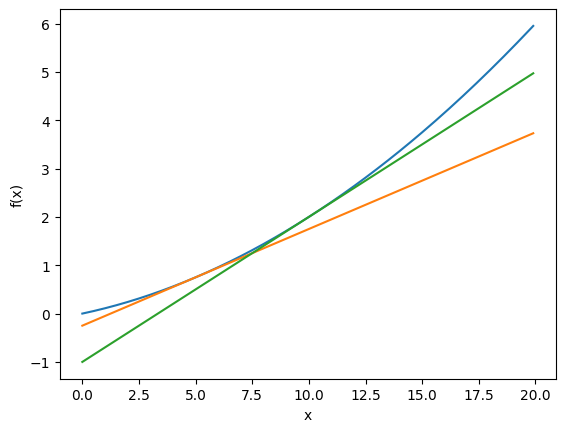

0.1999999999990898
0.2999999999986347


In [116]:
def function_1(x):
  return 0.01*x ** 2 + 0.1*x

import numpy as np
import matplotlib.pylab as plt

x = np.arange(0.0, 20.0, 0.1) # 0에서 20까지 0.1 간격의 배열 ×를 만든다(20은 미포함).
y = function_1(x)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.plot(x, y)
plt.plot(x, (x-5)*numerical_diff(function_1, 5) + function_1(5))
plt.plot(x, (x-10)*numerical_diff(function_1, 10) + function_1(10))
plt.show()

print(numerical_diff(function_1, 5))
# 0.1999999999990898
print(numerical_diff(function_1, 10))
# 0.2999999999986347

### 4.3.3 편미분
- 변수가 여럿인 함수에 대한 미분
$$ f(x_0, x_1) = x_0^2 + x_1^2$$

- 문제 1 : $x_0 = 3, x_1 = 4$ 일때, $x_0$에 대한 편미분을 구하여라

- 문제 2 : $x_0 = 3, x_1 = 4$ 일때, $x_1$에 대한 편미분을 구하여라


In [117]:
def function_2(x):
  return x[0]**2 + x[1]**2

def function_tmp1(x0):
  return x0*x0 + 4.0 ** 2.0

print(numerical_diff(function_tmp1, 3.0))
# 6.00000000000378

def function_tmp2(x1):
  return 3.0 ** 2.0 + x1*x1

print(numerical_diff(function_tmp2, 4.0))
# 7.999999999999119

6.00000000000378
7.999999999999119


# 4.4 기울기 (gradient)
- 모든 변수의 편미분을 벡터로 정리한것

In [118]:
def numerical_gradient(f, x):
  h = 1e-4 # 0.0001
  grad = np.zeros_like(x) # x와 형상이 같은 배열을 생성

  for idx in range(x.size):
    tmp_val = x[idx]

    # f(x+h) 계산
    x[idx] = tmp_val + h
    fxh1 = f(x)

    # f(x-h) 계산
    x[idx] = tmp_val - h
    fxh2 = f(x)

    grad[idx] = (fxh1 - fxh2) / (2*h)
    x[idx]= tmp_val # 값 복원

  return grad

In [119]:
print(numerical_gradient(function_2, np.array([3.0, 4.0])))
# array([ 6.,8.])
print(numerical_gradient(function_2, np.array([0.0, 2.0])))
# array([ 0.,4.])
print(numerical_gradient(function_2, np.array([3.0, 0.0])))
# array([ 6.,0.])

[6. 8.]
[0. 4.]
[6. 0.]


그림으로 보기 - 기울기의 결과에 마이너스를 붙인 벡터를 그린다면?

- 기울기는 함수의 가장 낮은 방향을 가리킨다.
- 가장 낮은 곳에서 멀어질 수록 화살표의 크기가 커진다.
> 기울기가 가리키는 쪽은 함수의 출력 값을 가장 크게 줄이는 방향

### 4.4.1 경사법(경사 하강법)
- 기울기를 이용해 손실함수가 최소가 되는 매개변수 값을 찾는것
### 경사법 (gradient method)
- 현 위치에서 기울기를 구함
- 기울어진 방향으로 일정거리 이동
- 반복

$$ x_0 = x_0 - \eta\frac{\partial f}{\partial x_0}$$
$$ x_1 = x_1 - \eta\frac{\partial f}{\partial x_1}$$

- $\eta$ 에타기호는 갱신하는 양을 나타냄 -> 이를 학습률(learning rate)이라고 함

In [120]:
def gradient_descent(f, init_x, lr=0.01, step_num=100):
  x = init_x

  for i in range(step_num):
    grad = numerical_gradient(f, x)
    x -= lr * grad
  return x

- f : 최적화 하려는 함수
- init_x : 초기값
- lr : learning rate 학습률,
- step_num : 경사법에 따른 반복 횟수

> 예시 문제 : 경사법으로 $f(x_0, x_1) = x_0^2 + x_1^2$ 의 최솟값을 구하라.
- 학습률이 너무 크면 큰 값으로 발산, 너무 작으면 거의 갱신 x

In [121]:
def function_2(x):
  return x[0] ** 2 + x[1] ** 2

init_x = np.array([-3.0, 4.0])
print(gradient_descent(function_2, init_x=init_x, lr=0.1, step_num=100))
# array([ -6.11110793e-10, 8.14814391e-10])

# 학습률이 너무 큰 예 : lr=10.0
init_x = np.array([-3.0, 4.0])
print(gradient_descent(function_2, init_x=init_x, lr=10.0, step_num=100))
# array([ -2.58983747e+13, -1.29524862e+12])

# 학습률이 너무 작은 예 : lr=1e-10
init_x = np.array([-3.0, 4.0])
print(gradient_descent(function_2, init_x=init_x, lr=1e-10, step_num=100))
# array([-2.99999994, 3.99999992])

[-6.11110793e-10  8.14814391e-10]
[-2.58983747e+13 -1.29524862e+12]
[-2.99999994  3.99999992]


## 4.4.2 신경망에서의 기울기
- 가중치 매개변수에 대한 손실함수의 기울기
- 형상이 2x3, 가중치가 W, 손실 함수가 L인 신경망
- 경사는 $\frac{\partial L}{\partial W}$
$$ W =
\begin{pmatrix}
w_{11} & w_{12} & w_{13}\\
w_{21} & w_{22} & w_{23}
\end{pmatrix}
$$

$$ \frac{\partial L}{\partial W} =  
\begin{pmatrix}
\frac{\partial L}{\partial w_{11}} & \frac{\partial L}{\partial w_{12}} & \frac{\partial L}{\partial w_{13}}\\
\frac{\partial L}{\partial w_{21}} & \frac{\partial L}{\partial w_{22}} & \frac{\partial L}{\partial w_{23}}
\end{pmatrix}
$$

In [122]:
import numpy as np
from common. functions import softmax, cross_entropy_error
from common.gradient import numerical_gradient

class simpleNet:
  def __init__(self):
    self.W= np.random.randn(2,3) # 정규분포로 초기화

  def predict(self, x):
    return np.dot(x, self.W)

  def loss(self, x, t):
    z = self.predict(x)
    y = softmax(z)
    loss = cross_entropy_error(y, t)

    return loss

simpleNet class
- 형상이 2x3인 가중치 매개변수 하나를 인스턴스 변수로 가짐
- predict(x) : 예측 수행
- loss(x,t) : 손실함수의 값을 구함

In [123]:
net = simpleNet()
print(net.W) # 가중치 매개변수

x= np.array([0.6, 0.9])
p = net.predict(x)
print(p)

np.argmax(p) # 최댓값의 인덱스


t = np.array([0, 0, 1]) # 정답 레이블
net.loss(x, t)

[[ 0.65651708  0.17253737  0.29716276]
 [ 0.93617995  1.41221316 -0.90801352]]
[ 1.23647221  1.37451427 -0.63891451]


np.float64(2.7088678747485946)

In [124]:
def f(W):
  return net.loss(x,t)

dW = numerical_gradient(f, net.W)
print(dW)

[[ 0.2607196   0.29931231 -0.56003191]
 [ 0.3910794   0.44896847 -0.84004787]]


- 기울기가 0.2 -> 가중치를 h만큼 늘리면 0.2h 만큼 손실함수의 값이 증가한다는 뜻
- 음의 방향으로 갱신해야함

# 4.5 학습 알고리즘 구현하기

### 전체
- 신경망에는 적용가능한 가중치와 편향이 있고, 이를 훈련 데이터에 적응하도록 조정하는 과정을 '학습' 이라고 함
### 1단계 - 미니배치
- 훈련 데이터 일부를 무작위로 가져옴 -> 미니배치
- 미니배치의 손실함수 값을 줄이는 것을 목표로함
### 2단계 - 기울기 산출
- 각 가중치 매개변수의 기울기를 구함
- 기울기는 손실 함수의 값을 가장 작게 하는 방향을 제시
### 3단계 - 매개변수 갱신
- 가중치 매개변수를 기울기 방향으로 아주 조금 갱신
### 4단계 - 반복
- 1~3단계 반복

## 확률적 경사 하강법 (SGD : Stochastic Gradient Descent)
- 데이터를 미니배치로 무작위로 선정

## 4.5.1 2층 신경망 클래스 구현하기

In [125]:
from common.functions import *
from common.gradient import numerical_gradient

class TwoLayerNet:
  def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01):
    # 가중치 초기화
    self.params = {}
    self.params['W1'] = weight_init_std * \
      np.random.randn(input_size, hidden_size)
    self.params['b1'] = np.zeros(hidden_size)
    self.params['W2'] = weight_init_std * \
      np.random.randn(hidden_size, output_size)
    self.params['b2'] = np.zeros(output_size)

  def predict(self, x):
    W1, W2 = self.params['W1'], self.params[ 'W2']
    b1, b2 = self.params['b1'], self.params['b2']

    a1 = np.dot(x, W1) + b1
    z1 = sigmoid(a1)
    a2= np.dot(z1, W2) + b2
    y = softmax(a2)

    return y

  # x: 입력 데이터, t: 정답 레이블
  def loss(self, x, t):
    y = self.predict(x)

    return cross_entropy_error(y, t)

  def accuracy(self, x, t):
    y = self.predict(x)
    y = np.argmax(y, axis=1)
    t = np.argmax(t, axis=1)

    accuracy = np.sum(y == t) / float(x.shape[0])
    return accuracy

  # x: 입력 데이터, t: 정답 레이블
  def numerical_gradient(self, x, t):
    loss_W = lambda W: self.loss(x, t)

    grads = {}
    grads['W1'] = numerical_gradient(loss_W, self.params['W1'])
    grads['b1'] = numerical_gradient(loss_W, self.params['b1'])
    grads['W2'] = numerical_gradient(loss_W, self.params['W2'])
    grads['b2'] =numerical_gradient(loss_W, self.params['b2'])

    return grads


### 4.5.2 미니배치 학습 구현하기
- 계산량이 너무 많은 가봄
- 실행이 너무 오래걸림

In [126]:
import numpy as np
from dataset.mnist import load_mnist

(x_train, t_train), (x_test, t_test) = \
  load_mnist(normalize=True, one_hot_label=True)

train_loss_list = []

# 하이퍼파라미터
iters_num = 10000 # 반복 횟수
train_size = x_train. shape [ 0]
batch_size = 100  # 미니배치 크기
learning_rate = 0.1

network = TwoLayerNet(input_size=784, hidden_size=50, output_size=10)

for i in range(iters_num):
  # 미니배치 획득
  batch_mask = np.random.choice(train_size, batch_size)
  x_batch = x_train[batch_mask]
  t_batch = t_train[batch_mask]

  # 기울기 계산
  grad = network.numerical_gradient(x_batch, t_batch)
  # grad = network.gradient(x_batch, t_batch) # 성능 개선판!

  # 매개변수 갱신
  for key in ('W1', 'b1', 'W2', 'b2'):
    network.params[key] -= learning_rate * grad[key]

  # 학습 경과 기록
  loss = network. loss(x_batch, t_batch)
  train_loss_list.append(loss)


KeyboardInterrupt



### 4.5.3 시험데이터로 평가하기
- 에포크 (epoch) : 하나의 단위
- 1에포크 : 학습에서 훈련 데이터를 모두 소진했을때의 횟수
>10000개의 훈련데이터를 100개의 미니배치로 학습
>
> -> 확률적 경사 하강법을 100회하면 데이터를 모두 소진한게 됨
>
> -> 이때는 100이 1에포크

In [ ]:
import numpy as np
from dataset.mnist import load_mnist

(x_train, t_train), (x_test, t_test) = \
  load_mnist(normalize=True, one_hot_label=True)

network = TwoLayerNet(input_size=784, hidden_size=50, output_size=10)

# 하이퍼파라미터
iters_num = 10000 # 반복 횟수를 적절히 설정한다.
train_size = x_train. shape[0]
batch_size = 100 # 미니배치 크기
learning_rate = 0.1

train_loss_list = []
train_acc_list = []
test_acc_list = []

# 1에포크당 반복 수
iter_per_epoch = max(train_size / batch_size, 1)

for i in range(iters_num):
  # 미니배치 획득
  batch_mask = np.random.choice(train_size, batch_size)
  x_batch = x_train[batch_mask]
  t_batch = t_train[batch_mask]

  # 기울기 계산
  grad = network.numerical_gradient(x_batch, t_batch)
  #grad = network.gradient(x_batch, t_batch) # 성능 개선판!

  # 매개변수 갱신
  for key in ('W1', 'b1', 'W2', 'b2'):
    network.params[key] -= learning_rate * grad[key]

  # 학습 경과 기록
  loss = network.loss(x_batch, t_batch)
  train_loss_list.append(loss)

  # 1에포크당 정확도 계산
  if i % iter_per_epoch == 0:
    train_acc = network.accuracy(x_train, t_train)
    test_acc = network.accuracy(x_test, t_test)
    train_acc_list.append(train_acc)
    test_acc_list. append(test_acc)
    print("train acc, test acc | "
    + str(train_acc) + ", "+ str(test_acc))